color_bar: #7cec34 | color_line: #48c490 | cmap_color: magma
(1000, 9)
                                     track_name                artist  duration_min
                                       Lost Boy                 Jaden      9.497883
                              I'm Getting Ready   Tasha Cobbs Leonard      8.436667
                                        Mirrors     Justin Timberlake      8.069100
What Goes Around.../...Comes Around (Interlude)     Justin Timberlake      7.476217
                             Achilles Come Down        Gang of Youths      7.035767
                           Never Let Go (Of Me)                Baltra      6.909833
          House Of Balloons / Glass Table Girls            The Weeknd      6.753550
                                           Stan                Eminem      6.735100
                                      Galvanize The Chemical Brothers      6.563550
                                    After Hours            The Weeknd      6.017100


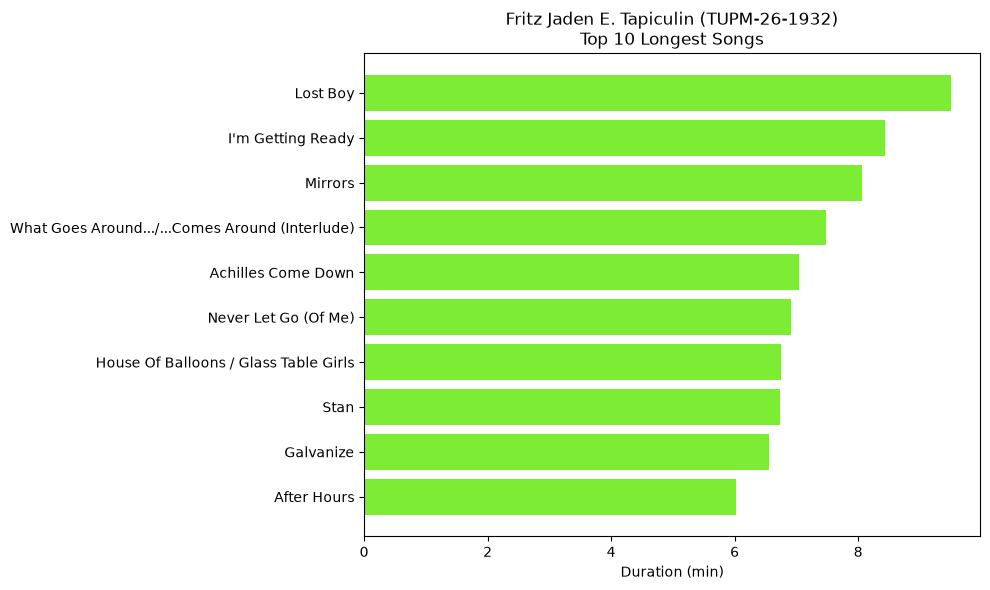

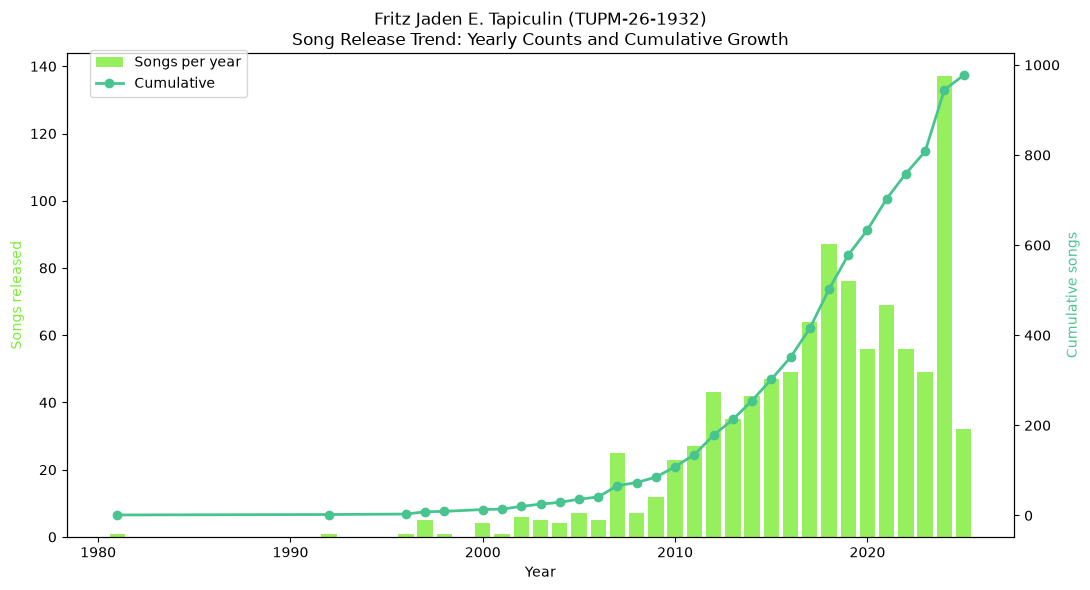

 year  count  cumulative
 2016     49         351
 2017     64         415
 2018     87         502
 2019     76         578
 2020     56         634
 2021     69         703
 2022     56         759
 2023     49         808
 2024    137         945
 2025     32         977
Animated hexbin saved: c:\Users\Fritz Tapiculin\Lab8_Data_Visualization\Lab8_Data_Visualization_Tapiculin\exercise3_density_animation.gif | frames: 31


In [2]:
# %% Shared setup (Spotify top 1000 tracks)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

student_name = "Fritz Jaden E. Tapiculin"
student_id = "TUPM-26-1932"
id_num = int(student_id[-3:])

# student-specific colors derived from the ID
def hexcolor(a, b, c):
    return f"#{(id_num * a) % 256:02x}{(id_num * b) % 256:02x}{(id_num * c) % 256:02x}"
color_bar = hexcolor(7, 3, 5)
color_line = hexcolor(2, 9, 4)
cmap_color = ["viridis", "plasma", "magma", "inferno", "cividis"][id_num % 5]
print("color_bar:", color_bar, "| color_line:", color_line, "| cmap_color:", cmap_color)

dataset_path = "spotify_top_1000_tracks.csv"
df = pd.read_csv(dataset_path, encoding="utf-8")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
for c in ("track_name", "artist"):
    df[c] = df[c].astype(str).str.strip()
print(df.shape)

# %% EXERCISE 1 - Identify Longest Tracks
longest = df.nlargest(10, "duration_min")[["track_name", "artist", "duration_min"]].reset_index(drop=True)
print(longest.to_string(index=False))                       # table: track name, artist, duration

plt.figure(figsize=(10, 6))
plt.barh(longest["track_name"], longest["duration_min"], color=color_bar)
plt.gca().invert_yaxis()
plt.xlabel("Duration (min)")
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Songs")
plt.tight_layout()
plt.savefig("exercise1_longest_tracks.png", dpi=150)
plt.show()

# %% EXERCISE 2 - Song Release Trend (bars + cumulative line)
yearly = df.dropna(subset=["year"]).groupby(df["year"].astype("Int64")).size().sort_index()
cumulative = yearly.cumsum()

fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.bar(yearly.index.astype(int), yearly.values, color=color_bar, alpha=0.8, label="Songs per year")
ax1.set_xlabel("Year")
ax1.set_ylabel("Songs released", color=color_bar)
ax2 = ax1.twinx()
ax2.plot(cumulative.index.astype(int), cumulative.values, color=color_line, marker="o", linewidth=2, label="Cumulative")
ax2.set_ylabel("Cumulative songs", color=color_line)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
plt.title(f"{student_name} ({student_id})\nSong Release Trend: Yearly Counts and Cumulative Growth")
fig.tight_layout()
fig.savefig("exercise2_release_trend.png", dpi=150)
plt.show()
print(pd.DataFrame({"year": yearly.index.astype(int), "count": yearly.values, "cumulative": cumulative.values}).tail(10).to_string(index=False))

# %% EXERCISE 3 - Animated Density Map (hexbin) of Duration vs Popularity
from matplotlib.animation import FuncAnimation, PillowWriter

data = df.dropna(subset=["year", "duration_min", "popularity"]).copy()
data["year"] = data["year"].astype(int)
years = sorted(data["year"].unique())
xlim = (data["duration_min"].min(), data["duration_min"].max())
ylim = (data["popularity"].min(), data["popularity"].max())

fig, ax = plt.subplots(figsize=(9, 6))

def draw(frame):
    ax.clear()
    subset = data[data["year"] <= years[frame]]          # evolves cumulatively by release year
    ax.hexbin(subset["duration_min"], subset["popularity"], gridsize=20, cmap=cmap_color,
              extent=(xlim[0], xlim[1], ylim[0], ylim[1]), mincnt=1)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("Duration (min)"); ax.set_ylabel("Popularity")
    ax.set_title(f"{student_name} ({student_id})\nDuration vs Popularity - songs up to {years[frame]} ({len(subset)} tracks)")

ani = FuncAnimation(fig, draw, frames=len(years), interval=300, repeat=False)
gif_path = os.path.abspath("exercise3_density_animation.gif")
ani.save(gif_path, writer=PillowWriter(fps=3))
plt.close(fig)
print("Animated hexbin saved:", gif_path, "| frames:", len(years))
